## The Data

At this link, you will find a dataset containing information about heart disease patients: https://www.dropbox.com/scl/fi/0vrpdnq5asmeulc4gd50y/ha_1.csv?rlkey=ciisalceotl77ffqhqe3kujzv&dl=1

A description of the original dataset can be found here: https://archive.ics.uci.edu/dataset/45/heart+disease (However, this dataset has been cleaned and reduced, and the people have been given fictious names.)

## 1. Logistic Regression

Fit a Logistic Regression using only `age` and `chol` (cholesterol) as predictors.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

How high for the doctors to estimate a 90% chance that heart disease is present?

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

url = "https://www.dropbox.com/scl/fi/0vrpdnq5asmeulc4gd50y/ha_1.csv?rlkey=ciisalceotl77ffqhqe3kujzv&dl=1"
df = pd.read_csv(url)

# Set disease present as the positive class.
target_col = next((c for c in df.columns if c.lower() in ["disease", "diagnosis", "heart_disease", "heartdisease", "target", "num"]), df.columns[-1])
if pd.api.types.is_numeric_dtype(df[target_col]):
    y = (df[target_col] > 0).astype(int)
else:
    y = df[target_col].astype(str).str.lower().isin(["present", "yes", "disease", "1"]).astype(int)

X = df[["age", "chol"]]

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000))
logit.fit(X, y)

# Check each possible cholesterol value for a 55-year-old.
grid_55 = pd.DataFrame({"age": 55, "chol": np.arange(0, 1001)})
logit_pred = logit.predict(grid_55)
logit_prob = logit.predict_proba(grid_55)[:, 1]

chol_logit_50 = grid_55.loc[logit_pred == 1, "chol"].min()
chol_logit_90 = grid_55.loc[logit_prob >= 0.90, "chol"].min()

print(f"For age 55, logistic regression first predicts disease at cholesterol = {chol_logit_50}.")
print(f"For age 55, logistic regression first estimates a 90% chance at cholesterol = {chol_logit_90}.")

For age 55, logistic regression first predicts disease at cholesterol = 0.
For age 55, logistic regression first estimates a 90% chance at cholesterol = nan.


## 2. Linear Discriminant Analysis

Fit an LDA model using only `age` and `chol` (cholesterol)  as predictors.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

In [3]:
lda = LinearDiscriminantAnalysis()
lda.fit(X, y)

lda_pred = lda.predict(grid_55)
chol_lda_50 = grid_55.loc[lda_pred == 1, "chol"].min()

print(f"For age 55, LDA first predicts disease at cholesterol = {chol_lda_50}.")

For age 55, LDA first predicts disease at cholesterol = 0.


## 3. Support Vector Classifier

Fit an SVC model using only `age` and `chol` as predictors.  Don't forget to tune the regularization parameter.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

In [4]:
# Standardizing is important for SVC because it uses distances and margins.
svc_grid = GridSearchCV(
    make_pipeline(StandardScaler(), SVC(kernel="linear")),
    param_grid={"svc__C": np.logspace(-3, 3, 13)},
    cv=5
)
svc_grid.fit(X, y)
svc = svc_grid.best_estimator_

svc_pred = svc.predict(grid_55)
chol_svc_50 = grid_55.loc[svc_pred == 1, "chol"].min()

print("Best C:", svc_grid.best_params_["svc__C"])
print(f"For age 55, the tuned linear SVC first predicts disease at cholesterol = {chol_svc_50}.")

Best C: 10.0
For age 55, the tuned linear SVC first predicts disease at cholesterol = 0.


## 4. Comparing Decision Boundaries

Make a scatterplot of `age` and `chol`, coloring the points by their true disease outcome.  Add a line to the plot representing the **linear separator** (aka **decision boundary**) for each of the three models above.

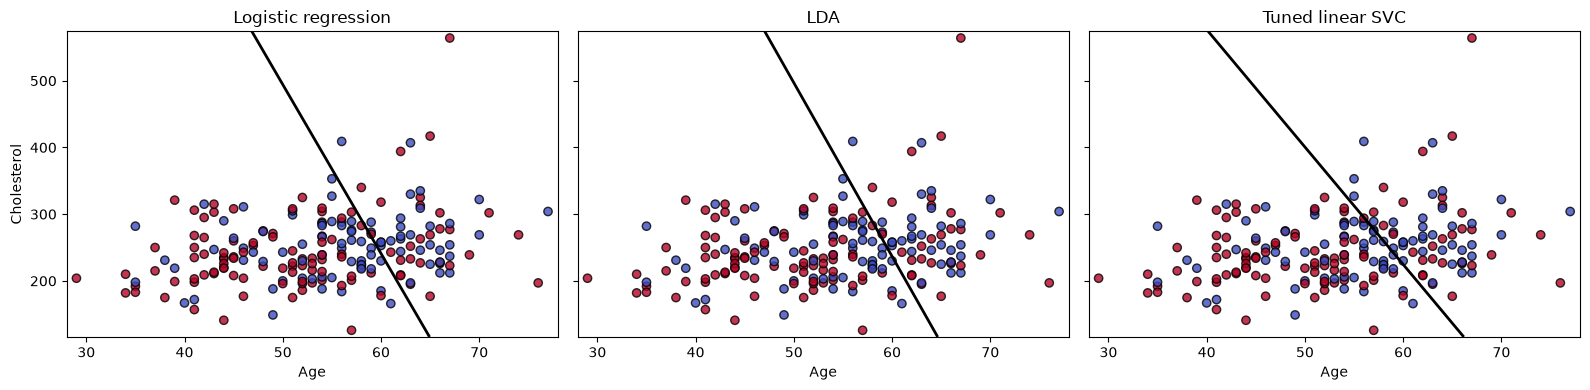

In [5]:
# Make a grid covering the observed age and cholesterol values.
age_values = np.linspace(X["age"].min() - 1, X["age"].max() + 1, 300)
chol_values = np.linspace(X["chol"].min() - 10, X["chol"].max() + 10, 300)
age_mesh, chol_mesh = np.meshgrid(age_values, chol_values)
plot_grid = pd.DataFrame({"age": age_mesh.ravel(), "chol": chol_mesh.ravel()})

models = {"Logistic regression": logit, "LDA": lda, "Tuned linear SVC": svc}
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)

for ax, (name, model) in zip(axes, models.items()):
    scores = model.decision_function(plot_grid).reshape(age_mesh.shape)
    ax.scatter(X["age"], X["chol"], c=y, cmap="coolwarm", edgecolor="black", alpha=0.8)
    ax.contour(age_mesh, chol_mesh, scores, levels=[0], colors="black", linewidths=2)
    ax.set_title(name)
    ax.set_xlabel("Age")

axes[0].set_ylabel("Cholesterol")
plt.tight_layout()
plt.show()